# Introduction to Machine Learning

## 1. What is Machine Learning?

Machine Learning is a branch of Artificial Intelligence that enables computers to learn patterns from data and make predictions without being explicitly programmed for every task.

## 2. Supervised Learning

Supervised learning uses labelled data, where input features and their corresponding output values are available.

Examples:
- House price prediction
- Student marks prediction
- Email spam classification

## 3. Unsupervised Learning

Unsupervised learning works with data that does not have predefined output labels. It identifies hidden patterns or groups.

Examples:
- Customer segmentation
- Clustering similar properties
- Grouping customers based on purchasing behaviour

## 4. Regression

Regression is used to predict continuous numerical values. In this project, regression algorithms estimate house prices using property characteristics.

## 5. Classification

Classification is used to predict categories or classes.

Examples:
- Spam or not spam
- Approved or rejected
- High-risk or low-risk customers

## 6. Model Training and Evaluation

Model training allows an algorithm to learn patterns from training data. Model evaluation measures how well the trained model performs on unseen data.

## 7. Train-Test Split

The dataset is divided into:
- Training data: 80%
- Testing data: 20%

The training data is used to build the model, while the testing data evaluates its performance.

## 8. Cross-Validation

Cross-validation divides training data into multiple subsets, called folds, to evaluate model performance more reliably. This project uses five-fold cross-validation.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("house_prices.csv")
print("Shape:", df.shape)
display(df.head())

Shape: (300, 8)


,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
0,PROP0001,3712,4,3,36,Rural,House,22260000
1,PROP0002,1591,4,1,35,Suburb,House,16057500
2,PROP0003,1646,4,3,20,Rural,Villa,12730000
3,PROP0004,4814,1,2,13,City Center,Villa,50840000
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000


In [38]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
print("Unique property IDs:", df["Property_ID"].nunique())
display(df.describe(include="all").T)

Data types:


,dtype
Property_ID,object
Area,int64
Bedrooms,int64
Bathrooms,int64
Age,int64
Location,object
Property_Type,object
Price,int64


Missing values:


,missing_count
Property_ID,0
Area,0
Bedrooms,0
Bathrooms,0
Age,0
Location,0
Property_Type,0
Price,0


Duplicate rows: 0
Unique property IDs: 300


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Property_ID,300,300,PROP0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,300.0,NaN,NaN,NaN,2759.7,1297.68143,520.0,1675.75,2738.0,3801.25,4999.0
Bedrooms,300.0,NaN,NaN,NaN,3.033333,1.467219,1.0,2.0,3.0,4.0,5.0
Bathrooms,300.0,NaN,NaN,NaN,2.026667,0.792495,1.0,1.0,2.0,3.0,3.0
Age,300.0,NaN,NaN,NaN,25.0,14.332646,0.0,12.0,25.5,36.25,49.0
Location,300,3,Suburb,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Property_Type,300,3,House,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,300.0,NaN,NaN,NaN,24883658.333333,12665254.724173,3695000.0,15277500.0,22365000.0,34608125.0,58700000.0


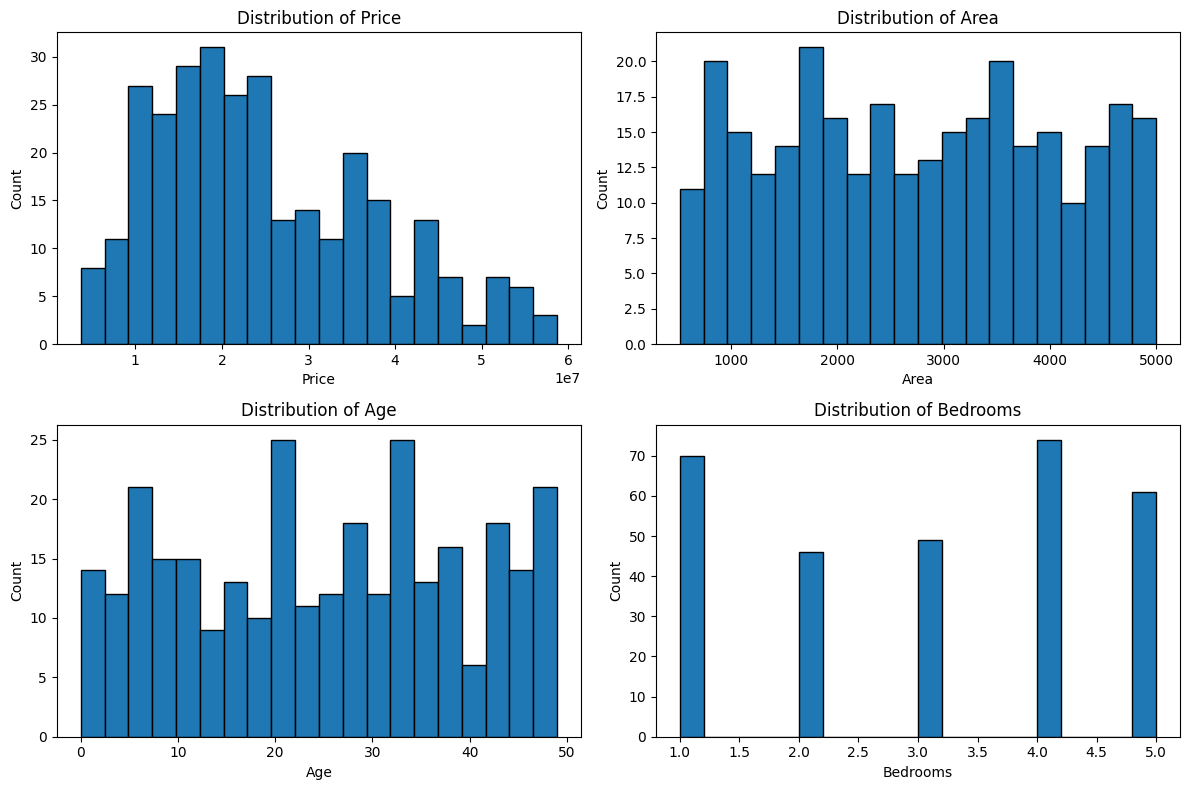

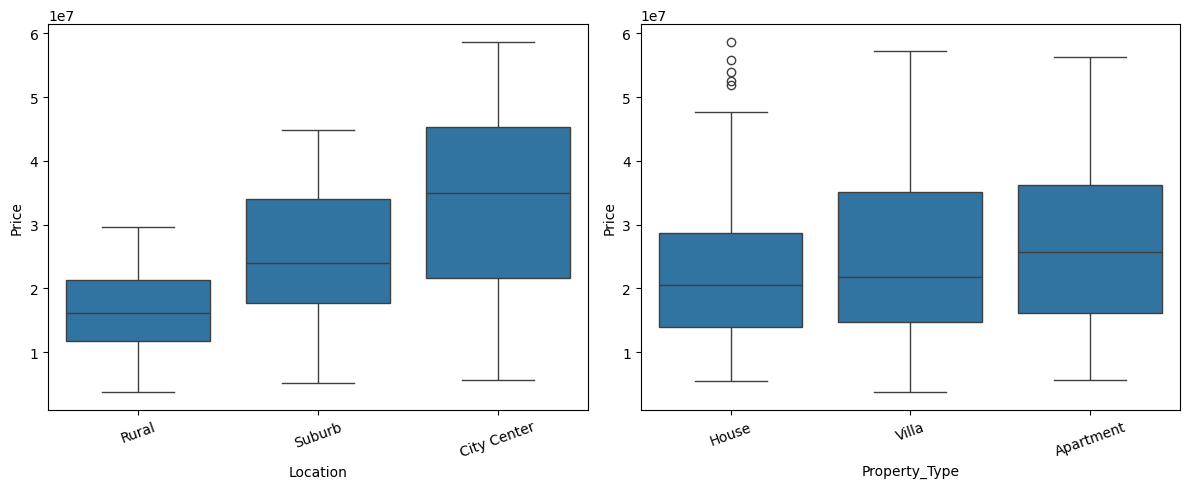

In [39]:
# Distribution of target and numeric features
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Price", "Area", "Age", "Bedrooms"]):
    ax.hist(df[col], bins=20, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

# Price by categorical groups
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="Location", y="Price", ax=axes[0])
sns.boxplot(data=df, x="Property_Type", y="Price", ax=axes[1])
axes[0].tick_params(axis="x", rotation=20)
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [40]:
target = "Price"
numeric_features = ["Area", "Bedrooms", "Bathrooms", "Age"]
categorical_features = ["Location", "Property_Type"]
X = df[numeric_features + categorical_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 240
Testing rows: 60


In [41]:
x = X_train["Area"].to_numpy(dtype=float)
y_one = y_train.to_numpy(dtype=float)

slope = np.sum((x - x.mean()) * (y_one - y_one.mean())) / np.sum((x - x.mean()) ** 2)
intercept = y_one.mean() - slope * x.mean()

print("Slope:", slope)
print("Intercept:", intercept)

x_test_area = X_test["Area"].to_numpy(dtype=float)
scratch_predictions = intercept + slope * x_test_area
print("First 5 predictions:", np.round(scratch_predictions[:5], 2))

Slope: 7889.31495636646
Intercept: 3162013.155608624
First 5 predictions: [ 8077056.37 30435374.96 37701434.03 21307437.56 25741232.56]


In [42]:
def make_preprocessor(polynomial=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if polynomial:
        numeric_steps.append(("poly", PolynomialFeatures(degree=2, include_bias=False)))
    numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features)
    ])

models = {
    "Linear Regression": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", LinearRegression())
    ]),
    "Polynomial Regression (degree 2)": Pipeline([
        ("preprocess", make_preprocessor(polynomial=True)),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", DecisionTreeRegressor(max_depth=5, min_samples_leaf=4, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, max_features=1.0,
            random_state=42, n_jobs=-1
        ))
    ])
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
        n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "CV_RMSE_Mean": -scores["test_rmse"].mean(),
        "CV_RMSE_Std": scores["test_rmse"].std(),
        "CV_R2_Mean": scores["test_r2"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV_RMSE_Mean")
display(cv_results)

,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_R2_Mean
3,Random Forest,2.258122e+06,171996.720385,0.967904
0,Linear Regression,2.736990e+06,202973.249815,0.952889
1,Polynomial Regression (degree 2),2.800960e+06,158218.982776,0.950851
2,Decision Tree,3.199979e+06,213880.700389,0.935124


In [43]:
best_name = cv_results.iloc[0]["Model"]
best_model = models[best_name]
best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

baseline_predictions = np.repeat(y_train.mean(), len(y_test))
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("Selected model:", best_name)
print(f"MAE:  {mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")
print(f"Mean-price baseline RMSE: {baseline_rmse:,.2f}")

Selected model: Random Forest
MAE:  1,599,658.06
MSE:  4,662,030,179,060.63
RMSE: 2,159,173.49
R²:   0.9673
Mean-price baseline RMSE: 11,939,075.90


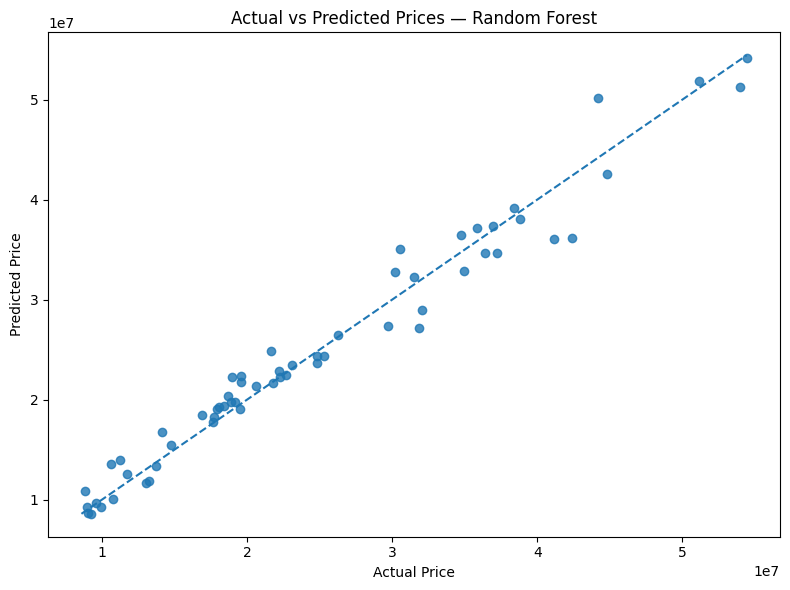

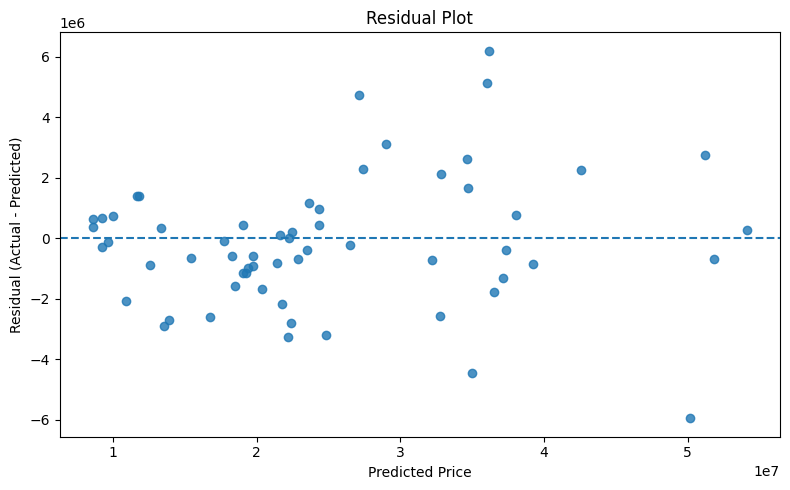

In [44]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.8)
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted Prices — {best_name}")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - predictions
plt.figure(figsize=(8, 5))
plt.scatter(predictions, residuals, alpha=0.8)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

In [45]:
import os

# Create folder
os.makedirs("visualization", exist_ok=True)

print("Visualization folder created successfully!")

Visualization folder created successfully!


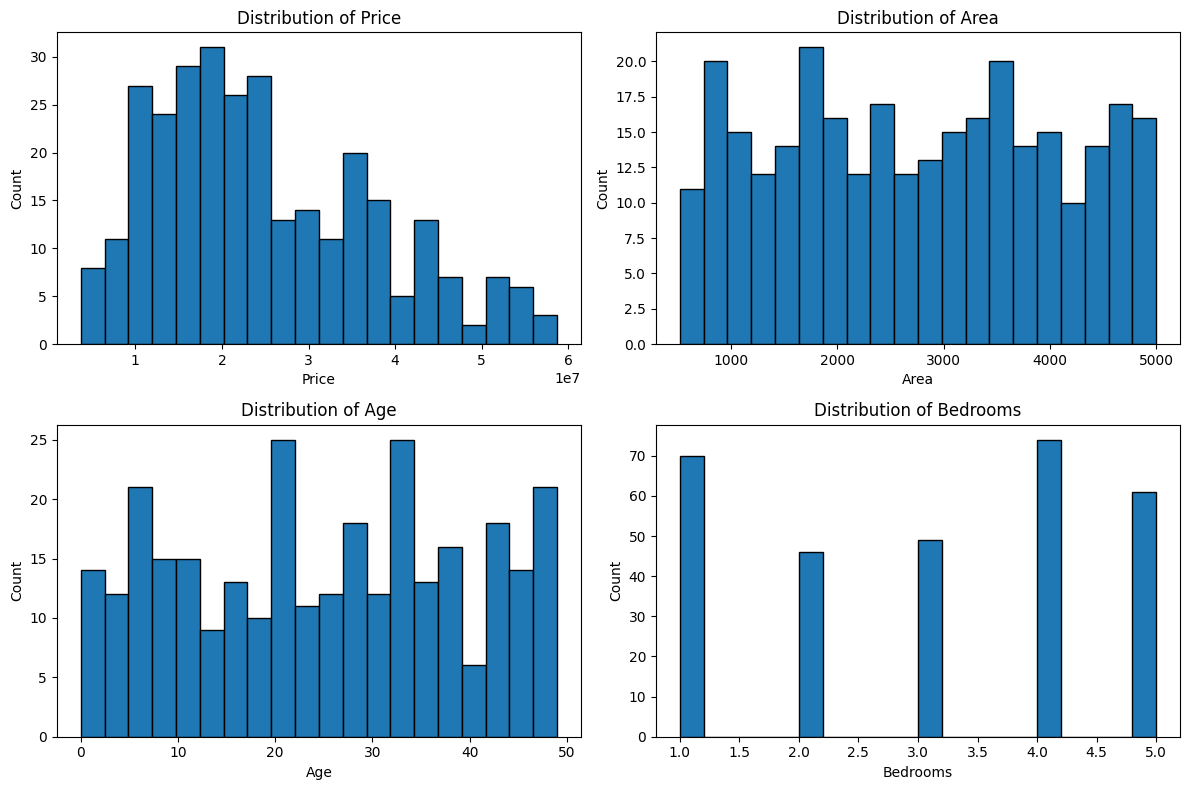

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.ravel(), ["Price", "Area", "Age", "Bedrooms"]):
    ax.hist(df[col], bins=20, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()

plt.savefig("visualization/01_feature_distributions.png",
            dpi=300, bbox_inches="tight")

plt.show()

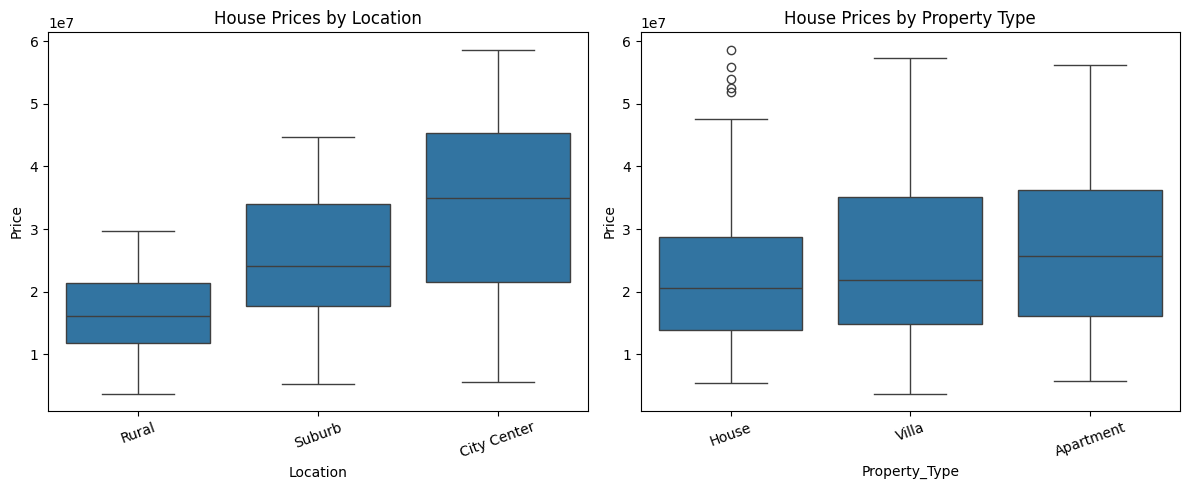

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Location", y="Price", ax=axes[0])
sns.boxplot(data=df, x="Property_Type", y="Price", ax=axes[1])

axes[0].set_title("House Prices by Location")
axes[1].set_title("House Prices by Property Type")

axes[0].tick_params(axis="x", rotation=20)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()

plt.savefig("visualization/02_price_by_categories.png",
            dpi=300, bbox_inches="tight")

plt.show()

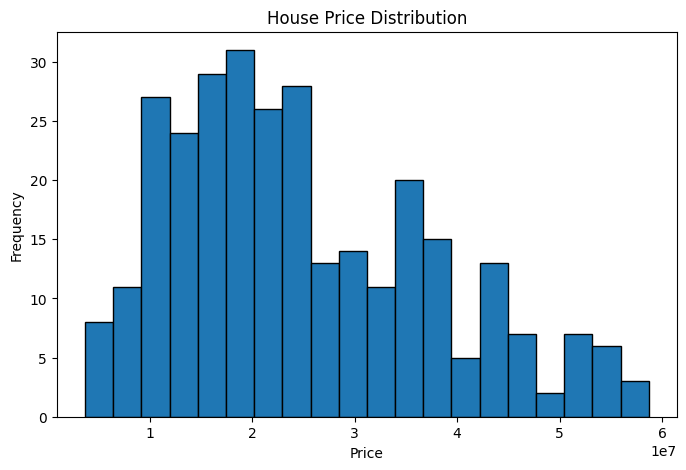

In [48]:
plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=20, edgecolor="black")
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.savefig("visualization/01_price_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

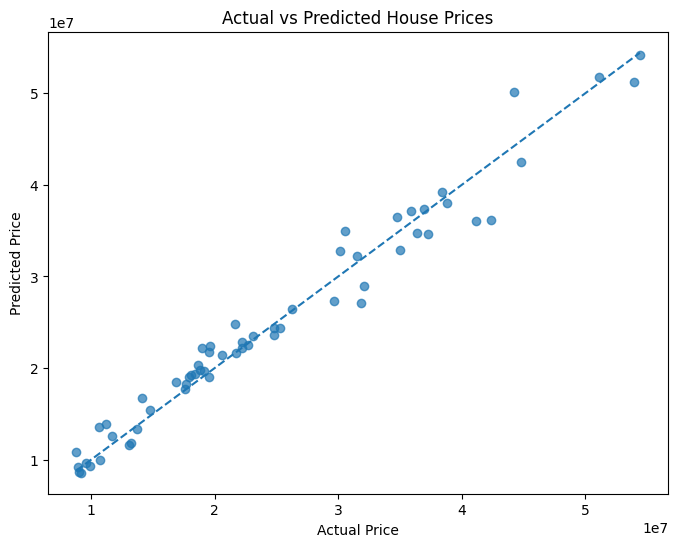

In [49]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.savefig("visualization/03_predictions_vs_actual.png",
            dpi=300, bbox_inches="tight")

plt.show()

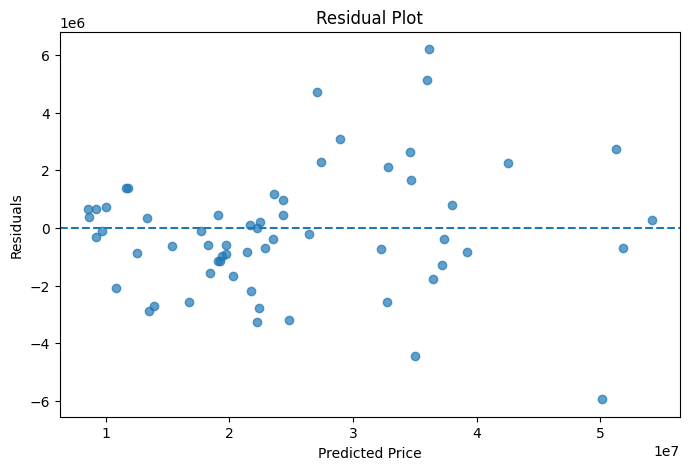

In [50]:
residuals = y_test.to_numpy() - predictions

plt.figure(figsize=(8, 5))

plt.scatter(predictions, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")

plt.savefig("visualization/04_residual_plot.png",
            dpi=300, bbox_inches="tight")

plt.show()

,Feature,Importance
0,num__Area,0.689119
4,cat__Location_City Center,0.154033
5,cat__Location_Rural,0.099524
6,cat__Location_Suburb,0.029922
1,num__Bedrooms,0.018434
3,num__Age,0.006269
2,num__Bathrooms,0.001198
9,cat__Property_Type_Villa,0.000635
7,cat__Property_Type_Apartment,0.000490
8,cat__Property_Type_House,0.000375


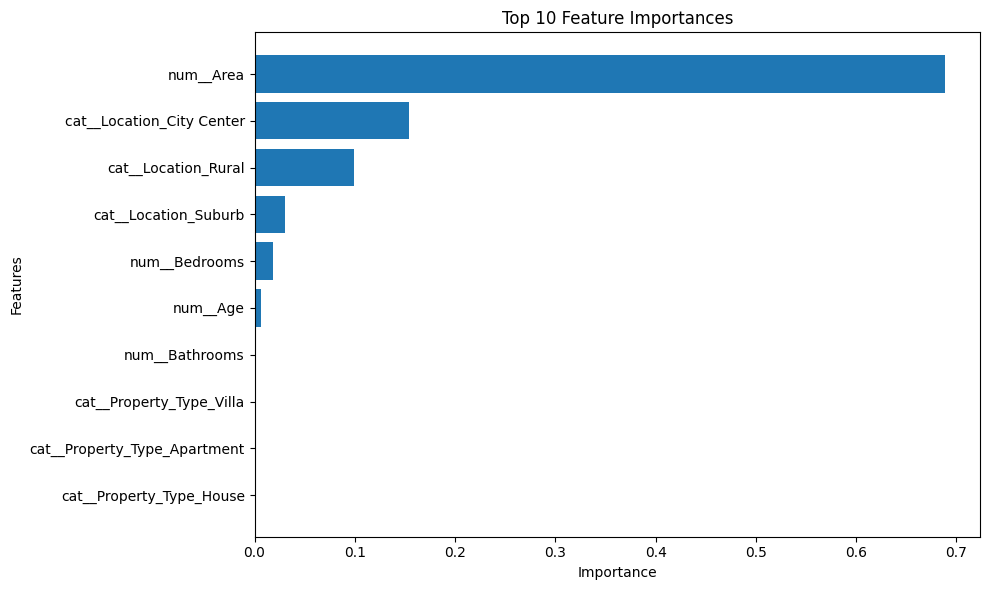

In [51]:
# Feature Importance Analysis

if best_name == "Random Forest":

    fitted_preprocessor = best_model.named_steps["preprocess"]
    fitted_model = best_model.named_steps["model"]

    feature_names = fitted_preprocessor.get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": fitted_model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    display(importance_df.head(10))

    plt.figure(figsize=(10, 6))

    top_features = importance_df.head(10).sort_values(
        by="Importance"
    )

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.title("Top 10 Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("Features")

    plt.tight_layout()

    plt.savefig(
        "visualization/05_feature_importance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("The selected model is not a Random Forest.")

### Feature Importance – Results and Interpretation

The Random Forest feature-importance analysis identifies Area as the most influential feature, with an importance score of approximately 0.6891.

Location is also an important predictor. The City Center and Rural categories have importance scores of approximately 0.1540 and 0.0995, respectively.

Bedrooms, Age and Bathrooms have comparatively smaller importance scores. Property Type contributes very little to the model's predictions in this dataset.

Overall, the analysis indicates that property area and location are the most influential features used by the trained Random Forest model to predict house prices.

In [52]:
# Predict the price of a sample property

sample_property = pd.DataFrame([{
    "Area": X_train["Area"].median(),
    "Bedrooms": X_train["Bedrooms"].mode()[0],
    "Bathrooms": X_train["Bathrooms"].mode()[0],
    "Age": X_train["Age"].median(),
    "Location": X_train["Location"].mode()[0],
    "Property_Type": X_train["Property_Type"].mode()[0]
}])

predicted_price = best_model.predict(sample_property)

print("Sample Property Details:")
display(sample_property)

print(
    f"Predicted House Price: {predicted_price[0]:,.2f}"
)

Sample Property Details:


,Area,Bedrooms,Bathrooms,Age,Location,Property_Type
0,2738.0,4,2,26.0,Suburb,House


Predicted House Price: 25,249,118.19


In [56]:
# Basic Model Validation Tests

assert len(X_train) + len(X_test) == len(df)

assert len(predictions) == len(y_test)

assert np.isfinite(predictions).all()

assert np.isfinite([mae, mse, rmse, r2]).all()

assert mae >= 0
assert mse >= 0
assert rmse >= 0

print("All validation tests passed successfully!")

print("\nTesting Summary")
print("-------------------------")
print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Predictions Generated:", len(predictions))
print("Sample Prediction:", f"{predicted_price[0]:,.2f}")

All validation tests passed successfully!

Testing Summary
-------------------------
Total Records: 300
Training Records: 240
Testing Records: 60
Predictions Generated: 60
Sample Prediction: 25,249,118.19


In [54]:
plt.savefig(
    "predictions_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>